# Diabetes Risk Prediction – Random Forest (Final Model)
**ICS 3202 – Project Deliverable 3**

**Group Members:**

Karanja Joy Wangari (189731)

Felicia Agwata (189807)

Audrey Ayieko (172827)

**Aim:** Predicts if a person is likely to have diabetes, give a risk %, and explain why.

**Steps (CRISP-DM):**
1. Business Understanding
2. Data Understanding
3. Data Preparation
4. Modelling
5. Evaluation
6. Deployment

Base model: Model_Base.ipynb

### Key terms
| Term | Meaning |
|---|---|
| Feature | An input, e.g. age, BMI |
| Target | What we predict: diabetes (1 = yes, 0 = no) |
| Training set | Data the model learns from |
| Test set | New data used to check the model |
| Random Forest | Many decision trees that vote |
| Accuracy | % of predictions that are correct |
| Precision | When it says "diabetes", how often it is right |
| Recall | % of real diabetes cases it catches |
| F1-score | Balance of precision and recall |
| Overfitting | Model memorises training data, fails on new data |
| Threshold | Cut-off risk for saying "diabetes" |

## Step 1: Business Understanding
- **Problem:** Many people have diabetes and don't know it.
- **Users:** Patients and nutritionists using our Diabetes Tracker app.
- **Model must:** predict Yes/No, give a risk %, explain the result, reject wrong input.
- **Goal:** High recall since missing a diabetic person is worse than a false alarm.

## Step 2: Data Understanding
- Dataset: **Diabetes Prediction Dataset**
- Libraries: pandas (tables), matplotlib (charts), sklearn (ML)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, ConfusionMatrixDisplay
import joblib

Uploading diabetes_prediction_dataset.csv:

In [2]:
from google.colab import files
uploaded = files.upload()

Saving diabetes_prediction_dataset.csv to diabetes_prediction_dataset.csv


In [3]:
df = pd.read_csv('diabetes_prediction_dataset.csv')
df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Size and data types:

In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print()
print(df.dtypes)

Rows: 100000
Columns: 9

gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object


**Columns:**
- `gender` – Female / Male / Other
- `age` – years
- `hypertension` – high blood pressure (1 = yes)
- `heart_disease` – 1 = yes
- `smoking_history` – never, former, current, not current, ever, No Info
- `bmi` – body mass index
- `HbA1c_level` – average blood sugar (last 2–3 months)
- `blood_glucose_level` – blood sugar now
- `diabetes` – **target** (1 = yes)

Summary stats:

In [5]:
df.describe().round(2)

,age,hypertension,heart_disease,bmi,HbA1c_level,blood_glucose_level,diabetes
count,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00,100000.00
mean,41.89,0.07,0.04,27.32,5.53,138.06,0.08
std,22.52,0.26,0.19,6.64,1.07,40.71,0.28
min,0.08,0.00,0.00,10.01,3.50,80.00,0.00
25%,24.00,0.00,0.00,23.63,4.80,100.00,0.00
50%,43.00,0.00,0.00,27.32,5.80,140.00,0.00
75%,60.00,0.00,0.00,29.58,6.20,159.00,0.00
max,80.00,1.00,1.00,95.69,9.00,300.00,1.00


Diabetes vs no diabetes:

diabetes
0    91500
1     8500
Name: count, dtype: int64

Percentage with diabetes: 8.5 %


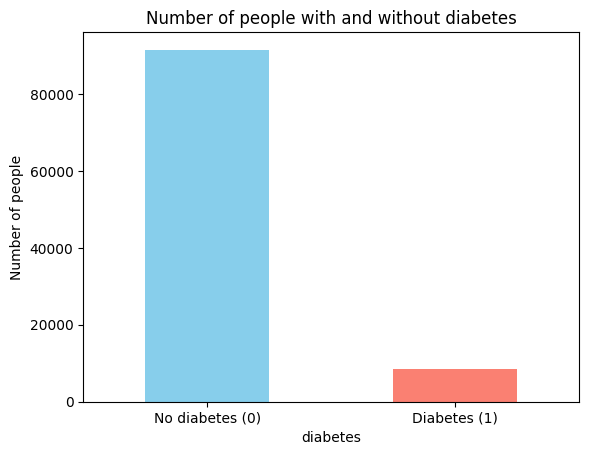

In [6]:
print(df['diabetes'].value_counts())
print()
print("Percentage with diabetes:", round(df['diabetes'].mean() * 100, 1), "%")

df['diabetes'].value_counts().plot(kind='bar', color=['skyblue', 'salmon'])
plt.title('Number of people with and without diabetes')
plt.xticks([0, 1], ['No diabetes (0)', 'Diabetes (1)'], rotation=0)
plt.ylabel('Number of people')
plt.show()

**Findings:**
- Only ~8.5% have diabetes → **imbalanced** data.
- So accuracy alone is not enough; we also check recall and F1.

HbA1c and glucose by diabetes status:

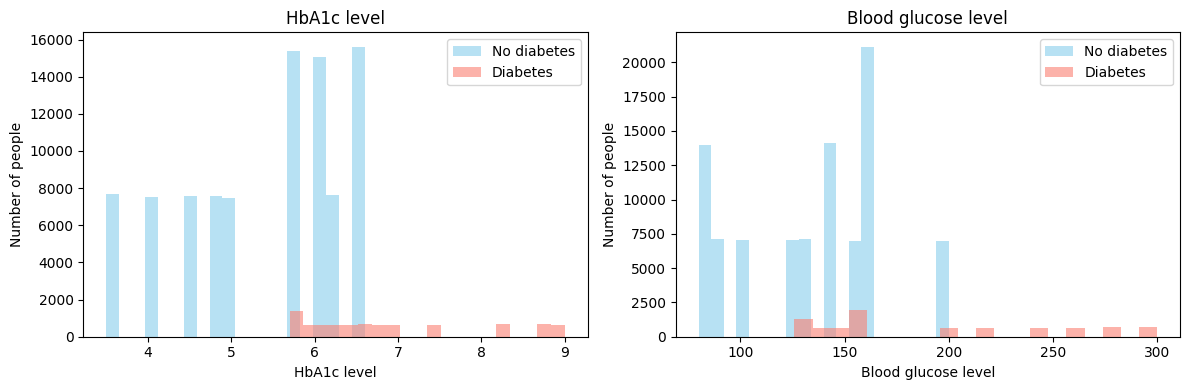

In [7]:
no_diabetes = df[df['diabetes'] == 0]
has_diabetes = df[df['diabetes'] == 1]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(no_diabetes['HbA1c_level'], bins=20, alpha=0.6, label='No diabetes', color='skyblue')
plt.hist(has_diabetes['HbA1c_level'], bins=20, alpha=0.6, label='Diabetes', color='salmon')
plt.title('HbA1c level')
plt.xlabel('HbA1c level')
plt.ylabel('Number of people')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(no_diabetes['blood_glucose_level'], bins=20, alpha=0.6, label='No diabetes', color='skyblue')
plt.hist(has_diabetes['blood_glucose_level'], bins=20, alpha=0.6, label='Diabetes', color='salmon')
plt.title('Blood glucose level')
plt.xlabel('Blood glucose level')
plt.ylabel('Number of people')
plt.legend()

plt.tight_layout()
plt.show()

In [8]:
# Average values for people without (0) and with (1) diabetes
df.groupby('diabetes')[['age', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'hypertension', 'heart_disease']].mean().round(2)

,age,bmi,HbA1c_level,blood_glucose_level,hypertension,heart_disease
diabetes,,,,,,
0,40.12,26.89,5.40,132.85,0.06,0.03
1,60.95,31.99,6.93,194.09,0.25,0.15


**Findings:**
- Diabetic people have much higher **HbA1c** and **glucose**.
- They are also older, with higher BMI and more hypertension/heart disease.

## Step 3: Data Preparation
### 3.1 Remove duplicates

In [9]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows after removing duplicates:", df.shape[0])

Duplicate rows: 3854
Rows after removing duplicates: 96146


### 3.2 Missing values

In [10]:
print(df.isnull().sum())

gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64


- No missing values.

### 3.3 Text to numbers
- Models only use numbers.
- We map `gender` and `smoking_history` ourselves so the app uses the same numbers.

In [11]:
gender_map = {'Female': 0, 'Male': 1, 'Other': 2}
smoking_map = {'never': 0, 'No Info': 1, 'current': 2, 'former': 3, 'ever': 4, 'not current': 5}

df['gender'] = df['gender'].map(gender_map)
df['smoking_history'] = df['smoking_history'].map(smoking_map)

df.head()

,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,0,80.0,0,1,0,25.19,6.6,140,0
1,0,54.0,0,0,1,27.32,6.6,80,0
2,1,28.0,0,0,0,27.32,5.7,158,0
3,0,36.0,0,0,2,23.45,5.0,155,0
4,1,76.0,1,1,2,20.14,4.8,155,0


### 3.4 Features (X) and target (y)

In [12]:
features = ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history',
            'bmi', 'HbA1c_level', 'blood_glucose_level']

X = df[features]
y = df['diabetes']

### 3.5 Train / validation / test split
- Train 60% – model learns
- Validation 20% – choose settings
- Test 20% – final check
- `stratify=y` keeps the same % of diabetes in each set

In [13]:
# First we take out 20% for the final test
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Then we split the rest into training (60% of all data) and validation (20% of all data)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print("Training set:  ", X_train.shape[0], "rows")
print("Validation set:", X_val.shape[0], "rows")
print("Test set:      ", X_test.shape[0], "rows")

Training set:   57687 rows
Validation set: 19229 rows
Test set:       19230 rows


## Step 4: Modelling
### 4.1 Base model: Logistic Regression

In [14]:
base_model = LogisticRegression(max_iter=1000)
base_model.fit(X_train, y_train)

base_pred = base_model.predict(X_val)
print("Logistic Regression on validation set")
print("Accuracy: ", round(accuracy_score(y_val, base_pred), 4))
print("Recall:   ", round(recall_score(y_val, base_pred), 4))
print("F1-score: ", round(f1_score(y_val, base_pred), 4))

Logistic Regression on validation set
Accuracy:  0.9585
Recall:    0.6279
F1-score:  0.7275


### 4.2 Final model: Random Forest
- Best model in Deliverable 2.
- Many trees ask yes/no questions such as  "HbA1c > 6.5?" and vote.
- Risk % = share of trees that vote "diabetes".

Testing different tree depths (`max_depth`):

In [15]:
for depth in [4, 8, 12, 16, None]:
    rf = RandomForestClassifier(n_estimators=100, max_depth=depth, random_state=42)
    rf.fit(X_train, y_train)
    pred = rf.predict(X_val)
    print("max_depth =", depth, " -> F1-score:", round(f1_score(y_val, pred), 4),
          " Recall:", round(recall_score(y_val, pred), 4))

max_depth = 4  -> F1-score: 0.8027  Recall: 0.6704
max_depth = 8  -> F1-score: 0.8027  Recall: 0.6704
max_depth = 12  -> F1-score: 0.805  Recall: 0.6769
max_depth = 16  -> F1-score: 0.8035  Recall: 0.6822
max_depth = None  -> F1-score: 0.7956  Recall: 0.6875


- Depth 4–16 → F1 ≈ 0.80.
- No limit (`None`) → lower → overfitting.
- **Chosen:** `max_depth = 12`, 200 trees.

In [16]:
model = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42)
model.fit(X_train, y_train)
print("Model trained!")

Model trained!


### 4.3 Choosing the threshold
- Default = 0.5. We test lower values to catch more cases.

In [17]:
val_risk = model.predict_proba(X_val)[:, 1]   # risk of diabetes for each person (0 to 1)

for threshold in [0.5, 0.4, 0.3, 0.2]:
    pred = np.where(val_risk >= threshold, 1, 0)   # 1 if risk is above the threshold, else 0
    print("Threshold", threshold,
          " Precision:", round(precision_score(y_val, pred), 3),
          " Recall:", round(recall_score(y_val, pred), 3),
          " F1:", round(f1_score(y_val, pred), 3))

Threshold 0.5  Precision: 0.994  Recall: 0.674  F1: 0.803
Threshold 0.4  Precision: 0.975  Recall: 0.688  F1: 0.807
Threshold 0.3  Precision: 0.903  Recall: 0.713  F1: 0.797
Threshold 0.2  Precision: 0.729  Recall: 0.788  F1: 0.757


- **Chosen: 0.3** → higher recall, precision still ~90%.
- 0.2 gives too many false alarms.

In [18]:
THRESHOLD = 0.3

## Step 5: Evaluation
Base vs final model on the test set:

In [19]:
# Random Forest predictions using our threshold of 0.3
test_risk = model.predict_proba(X_test)[:, 1]
rf_pred = np.where(test_risk >= THRESHOLD, 1, 0)

# Logistic Regression predictions
lr_pred = base_model.predict(X_test)

results = pd.DataFrame({
    'Model': ['Logistic Regression (base)', 'Random Forest (final)'],
    'Accuracy': [accuracy_score(y_test, lr_pred), accuracy_score(y_test, rf_pred)],
    'Precision': [precision_score(y_test, lr_pred), precision_score(y_test, rf_pred)],
    'Recall': [recall_score(y_test, lr_pred), recall_score(y_test, rf_pred)],
    'F1-score': [f1_score(y_test, lr_pred), f1_score(y_test, rf_pred)],
})
results.round(4)

,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression (base),0.9591,0.8658,0.6350,0.7327
1,Random Forest (final),0.9682,0.9039,0.7152,0.7986


- **Random Forest is better on every metric.**

### Confusion matrix

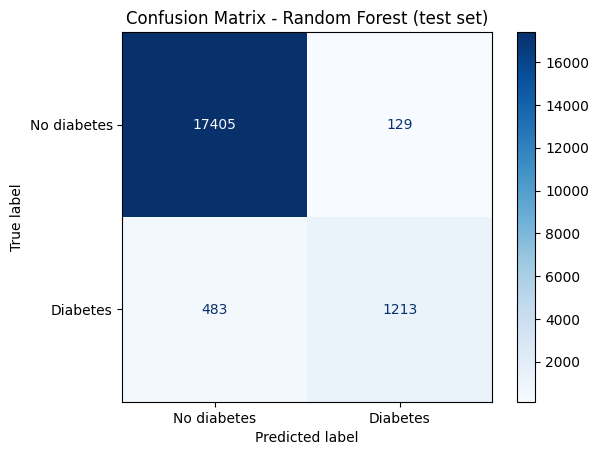

In [20]:
ConfusionMatrixDisplay.from_predictions(y_test, rf_pred, display_labels=['No diabetes', 'Diabetes'], cmap='Blues')
plt.title('Confusion Matrix - Random Forest (test set)')
plt.show()

### Cross-validation (5-fold)
- Train and test 5 times on different parts of the data.

In [21]:
cv_model = RandomForestClassifier(n_estimators=100, max_depth=12, random_state=42)
scores = cross_val_score(cv_model, X, y, cv=5, scoring='f1')
print("F1-score in each round:", scores.round(4))
print("Average F1-score:", round(scores.mean(), 4))

F1-score in each round: [0.8058 0.8092 0.7859 0.8122 0.8032]
Average F1-score: 0.8032


- Scores are close so the model is **stable**.

### Feature importance

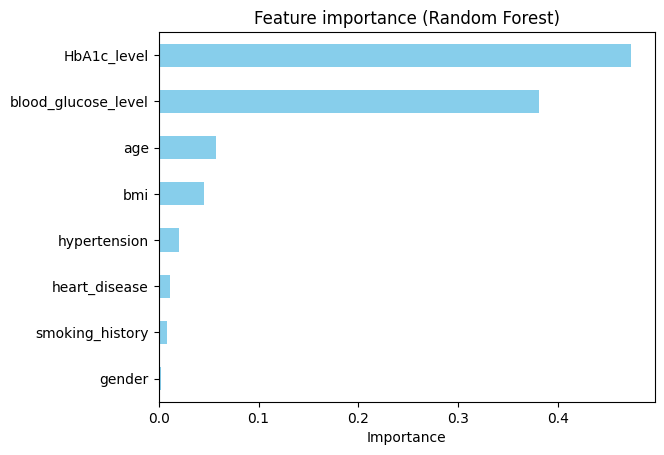

HbA1c_level            47.3
blood_glucose_level    38.1
age                     5.8
bmi                     4.5
hypertension            2.1
heart_disease           1.2
smoking_history         0.9
gender                  0.3
dtype: float64


In [22]:
importance = pd.Series(model.feature_importances_, index=features).sort_values()

importance.plot(kind='barh', color='skyblue')
plt.title('Feature importance (Random Forest)')
plt.xlabel('Importance')
plt.show()

print((importance.sort_values(ascending=False) * 100).round(1))

- **HbA1c** and **glucose** matter most, then age and BMI.
- This matches medical knowledge.

## Step 6: Deployment
Functions used by the app backend:
1. `check_input()` – rejects invalid input
2. `explain()` – Explainable AI
3. `predict_patient()` – returns the result

### 6.1 Input validation

In [24]:
# This function checks if a value can be turned into a number
def is_number(value):
    try:
        float(value)
        return True
    except:
        return False


def check_input(patient):
    errors = []
    warnings = []

    # 1. Check that every field is filled in
    for field in features:
        if field not in patient or patient[field] == '' or patient[field] is None:
            errors.append(field + " is missing")

    # if something is missing we stop here
    if len(errors) > 0:
        return errors, warnings

    # 2. Check the text options
    if patient['gender'] not in gender_map:
        errors.append("gender must be Female, Male or Other")

    if patient['smoking_history'] not in smoking_map:
        errors.append("smoking_history must be one of: never, No Info, current, former, ever, not current")

    # 3. Check yes/no fields are 0 or 1
    if str(patient['hypertension']) not in ['0', '1']:
        errors.append("hypertension must be 0 (No) or 1 (Yes)")

    if str(patient['heart_disease']) not in ['0', '1']:
        errors.append("heart_disease must be 0 (No) or 1 (Yes)")

    # 4. Check the numbers are real numbers and in a realistic range
    if not is_number(patient['age']):
        errors.append("age must be a number")
    elif float(patient['age']) < 1 or float(patient['age']) > 120:
        errors.append("age must be between 1 and 120")

    if not is_number(patient['bmi']):
        errors.append("bmi must be a number")
    elif float(patient['bmi']) < 10 or float(patient['bmi']) > 100:
        errors.append("bmi must be between 10 and 100")

    if not is_number(patient['HbA1c_level']):
        errors.append("HbA1c_level must be a number")
    elif float(patient['HbA1c_level']) < 3 or float(patient['HbA1c_level']) > 20:
        errors.append("HbA1c_level must be between 3 and 20")

    if not is_number(patient['blood_glucose_level']):
        errors.append("blood_glucose_level must be a number")
    elif float(patient['blood_glucose_level']) < 20 or float(patient['blood_glucose_level']) > 600:
        errors.append("blood_glucose_level must be between 20 and 600")

    # 5. Warn the user but still predict if a value is outside what the model saw in training
    if len(errors) == 0:
        if float(patient['age']) > 80:
            warnings.append("Age above 80 is outside our training data, so the result is less reliable")
        if float(patient['HbA1c_level']) > 9:
            warnings.append("HbA1c above 9 is outside our training data, so the result is less reliable")
        if float(patient['blood_glucose_level']) > 300:
            warnings.append("Glucose above 300 is outside our training data, so the result is less reliable")

    return errors, warnings

### 6.2 Explainable AI (what-if)
- For each detail, set it to a healthy value and predict again.
- Risk drop = how much that detail adds to the risk.

In [25]:
healthy_values = {
    'age': 30,
    'hypertension': 0,
    'heart_disease': 0,
    'smoking_history': 'never',
    'bmi': 22,
    'HbA1c_level': 5.0,
    'blood_glucose_level': 100,
}

def make_row(patient):
    # Turns the patient's details into a one-row table the model understands
    row = {
        'gender': gender_map[patient['gender']],
        'age': float(patient['age']),
        'hypertension': int(patient['hypertension']),
        'heart_disease': int(patient['heart_disease']),
        'smoking_history': smoking_map[patient['smoking_history']],
        'bmi': float(patient['bmi']),
        'HbA1c_level': float(patient['HbA1c_level']),
        'blood_glucose_level': float(patient['blood_glucose_level']),
    }
    return pd.DataFrame([row])[features]

def explain(patient, risk):
    reasons = []
    for field in healthy_values:
        # make a copy of the patient and change only ONE value to the healthy value
        what_if = patient.copy()
        what_if[field] = healthy_values[field]

        # predict again and see how much the risk dropped
        new_risk = model.predict_proba(make_row(what_if))[0][1]
        effect = (risk - new_risk) * 100

        # only keep details that add at least 1% to the risk
        if effect >= 1:
            reasons.append([field, str(patient[field]), round(effect, 1)])

    # put the biggest reason first
    reasons_table = pd.DataFrame(reasons, columns=['feature', 'value', 'effect'])
    reasons_table = reasons_table.sort_values('effect', ascending=False)
    return reasons_table.values.tolist()

### 6.3 Prediction function

In [26]:
def predict_patient(patient):
    errors, warnings = check_input(patient)
    if len(errors) > 0:
        return {'status': 'error', 'errors': errors}

    risk = model.predict_proba(make_row(patient))[0][1]

    if risk >= THRESHOLD:
        result = 'Likely diabetic'
    else:
        result = 'Unlikely diabetic'

    if risk >= THRESHOLD:
        level = 'High'
    elif risk >= 0.1:
        level = 'Moderate'
    else:
        level = 'Low'

    return {
        'status': 'ok',
        'result': result,
        'risk_percent': round(risk * 100, 1),
        'risk_level': level,
        'reasons': explain(patient, risk),
        'warnings': warnings,
        'note': 'This is a screening estimate, not a medical diagnosis. Please see a doctor.'
    }

def show(output):
    # Prints the result in a readable way how the app shows it
    if output['status'] == 'error':
        print("INVALID INPUT - no prediction made:")
        for e in output['errors']:
            print("  -", e)
        return
    print("Result:", output['result'])
    print("Risk:", output['risk_percent'], "% (" + output['risk_level'] + ")")
    if len(output['reasons']) > 0:
        print("Why? These details raised the risk:")
        for field, value, effect in output['reasons']:
            print("  -", field, "=", value, "-> adds about", effect, "%")
    else:
        print("Why? Your details are close to healthy levels, so nothing raised the risk much.")
    for w in output['warnings']:
        print("Warning:", w)

### 6.4 Testing
**Test 1: High risk**

In [27]:
person1 = {'gender': 'Male', 'age': 62, 'hypertension': 1, 'heart_disease': 0,
           'smoking_history': 'former', 'bmi': 33.5, 'HbA1c_level': 7.5, 'blood_glucose_level': 220}
show(predict_patient(person1))

Result: Likely diabetic
Risk: 100.0 % (High)
Why? These details raised the risk:
  - HbA1c_level = 7.5 -> adds about 26.5 %
  - blood_glucose_level = 220 -> adds about 21.5 %


- Both HbA1c and glucose are high, so fixing one still leaves high risk (effects don't add up to 100%).

**Test 2: Low risk**

In [28]:
person2 = {'gender': 'Female', 'age': 24, 'hypertension': 0, 'heart_disease': 0,
           'smoking_history': 'never', 'bmi': 22.0, 'HbA1c_level': 5.0, 'blood_glucose_level': 100}
show(predict_patient(person2))

Result: Unlikely diabetic
Risk: 0.0 % (Low)
Why? Your details are close to healthy levels, so nothing raised the risk much.


**Test 3: In-between (prediabetes HbA1c)**

In [29]:
person3 = {'gender': 'Female', 'age': 50, 'hypertension': 0, 'heart_disease': 0,
           'smoking_history': 'never', 'bmi': 29.0, 'HbA1c_level': 6.2, 'blood_glucose_level': 155}
show(predict_patient(person3))

Result: Unlikely diabetic
Risk: 3.9 % (Low)
Why? These details raised the risk:
  - HbA1c_level = 6.2 -> adds about 3.4 %
  - blood_glucose_level = 155 -> adds about 3.1 %
  - age = 50 -> adds about 2.4 %
  - bmi = 29.0 -> adds about 1.9 %


**Test 4: Test 3 but HbA1c = 6.8**

In [30]:
person4 = person3.copy()
person4['HbA1c_level'] = 6.8
show(predict_patient(person4))

Result: Likely diabetic
Risk: 97.6 % (High)
Why? These details raised the risk:
  - HbA1c_level = 6.8 -> adds about 97.1 %
  - blood_glucose_level = 155 -> adds about 12.1 %
  - bmi = 29.0 -> adds about 2.0 %


- Risk jumps from low to high (6.5 is the medical cut-off for diabetes).

**Test 5: Invalid input**

In [31]:
person5 = {'gender': 'Robot', 'age': -5, 'hypertension': 0, 'heart_disease': 0,
           'smoking_history': 'never', 'bmi': 25, 'HbA1c_level': 5.5, 'blood_glucose_level': 'abc'}
show(predict_patient(person5))

INVALID INPUT - no prediction made:
  - gender must be Female, Male or Other
  - age must be between 1 and 120
  - blood_glucose_level must be a number


**Test 6: Missing field**

In [32]:
person6 = {'gender': 'Male', 'age': 40, 'hypertension': 0, 'heart_disease': 0,
           'smoking_history': 'current', 'bmi': '', 'HbA1c_level': 5.8, 'blood_glucose_level': 140}
show(predict_patient(person6))

INVALID INPUT - no prediction made:
  - bmi is missing


**Test 7: Unusual input (age > 80)** – predicts but warns

In [33]:
person7 = {'gender': 'Female', 'age': 95, 'hypertension': 1, 'heart_disease': 1,
           'smoking_history': 'never', 'bmi': 27, 'HbA1c_level': 6.0, 'blood_glucose_level': 140}
show(predict_patient(person7))

Result: Unlikely diabetic
Risk: 25.8 % (Moderate)
Why? These details raised the risk:
  - HbA1c_level = 6.0 -> adds about 21.1 %
  - blood_glucose_level = 140 -> adds about 20.5 %
  - bmi = 27 -> adds about 8.0 %
  - heart_disease = 1 -> adds about 7.0 %
  - hypertension = 1 -> adds about 2.3 %
  - age = 95 -> adds about 1.2 %


### 6.5 Save model for the app

In [37]:
# We saved the model together with everything the app needs to use it
model_package = {
    'model': model,
    'features': features,
    'gender_map': gender_map,
    'smoking_map': smoking_map,
    'threshold': THRESHOLD,
    'healthy_values': healthy_values,
}
joblib.dump(model_package, 'diabetes_model.pkl')
print("Model saved as diabetes_model.pkl")

import sklearn
print("scikit-learn version:"), sklearn.__version__, "(the app uses this version to load the model)"

files.download('diabetes_model.pkl')

Model saved as diabetes_model.pkl
scikit-learn version:


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Summary
- **Model:** Random Forest (200 trees, depth 12, threshold 0.3)
- **Results:** Accuracy 96.8%, Precision 90.4%, Recall 71.5%, F1 0.80
- **Beats** base Logistic Regression on all metrics
- **Top features:** HbA1c, glucose
- **XAI:** shows which details raised the risk
- **Validation:** rejects missing/wrong values, warns on unusual ones
- **Limitation:** imbalanced data and it is a screening tool not a diagnosis